# TCGA-LUAD HE stromal-immune styled survival curve

Replots the current available-slide HE stromal-immune Kaplan-Meier curve with 95% confidence shading, bold left/bottom axes, no grid lines, and HR/P annotation.

In [1]:
import omicverse as ov
import scanpy as sc
import matplotlib.pyplot as plt
ov.plot_set(font_path='Arial')
sc.settings.set_figure_params(dpi=300, vector_friendly=True)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/_utils/__init__.py:33: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  from anndata import __version__ as anndata_version
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/__init__.py:24: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/scanpy/readwrite.py:16: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  if Version(anndata.__version__) >= Version("0.11.0rc2"):
/opt/miniforge/envs/omicverse_working/lib/python3.11/site-packages/louvain/__init__.py:54: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early

🔬 Starting plot initialization...
Using already downloaded Arial font from: /tmp/omicverse_arial.ttf
Registered as: Arial
🧬 Detecting GPU devices…
✅ NVIDIA CUDA GPUs detected: 8
    • [CUDA 0] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 1] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 2] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 3] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 4] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 5] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 6] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 7] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9

   ____            _     _    __                  
  / __ \____ ___  (_)___| |  / /__  _____________ 
 / / / / __ `__ \/ / ___/ | / / _ \/ ___/ ___/ _ \ 
/ /_/ / / / / / / / /__ | |/ /  __/ /  (__ 

🔬 Starting plot initialization...
Using already downloaded Arial font from: /tmp/omicverse_arial.ttf
Registered as: Arial
🧬 Detecting GPU devices…
✅ NVIDIA CUDA GPUs detected: 8
    • [CUDA 0] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 1] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 2] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 3] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 4] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 5] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 6] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
    • [CUDA 7] NVIDIA GeForce RTX 4090 D
      Memory: 23.5 GB | Compute: 8.9
✅ plot_set complete.



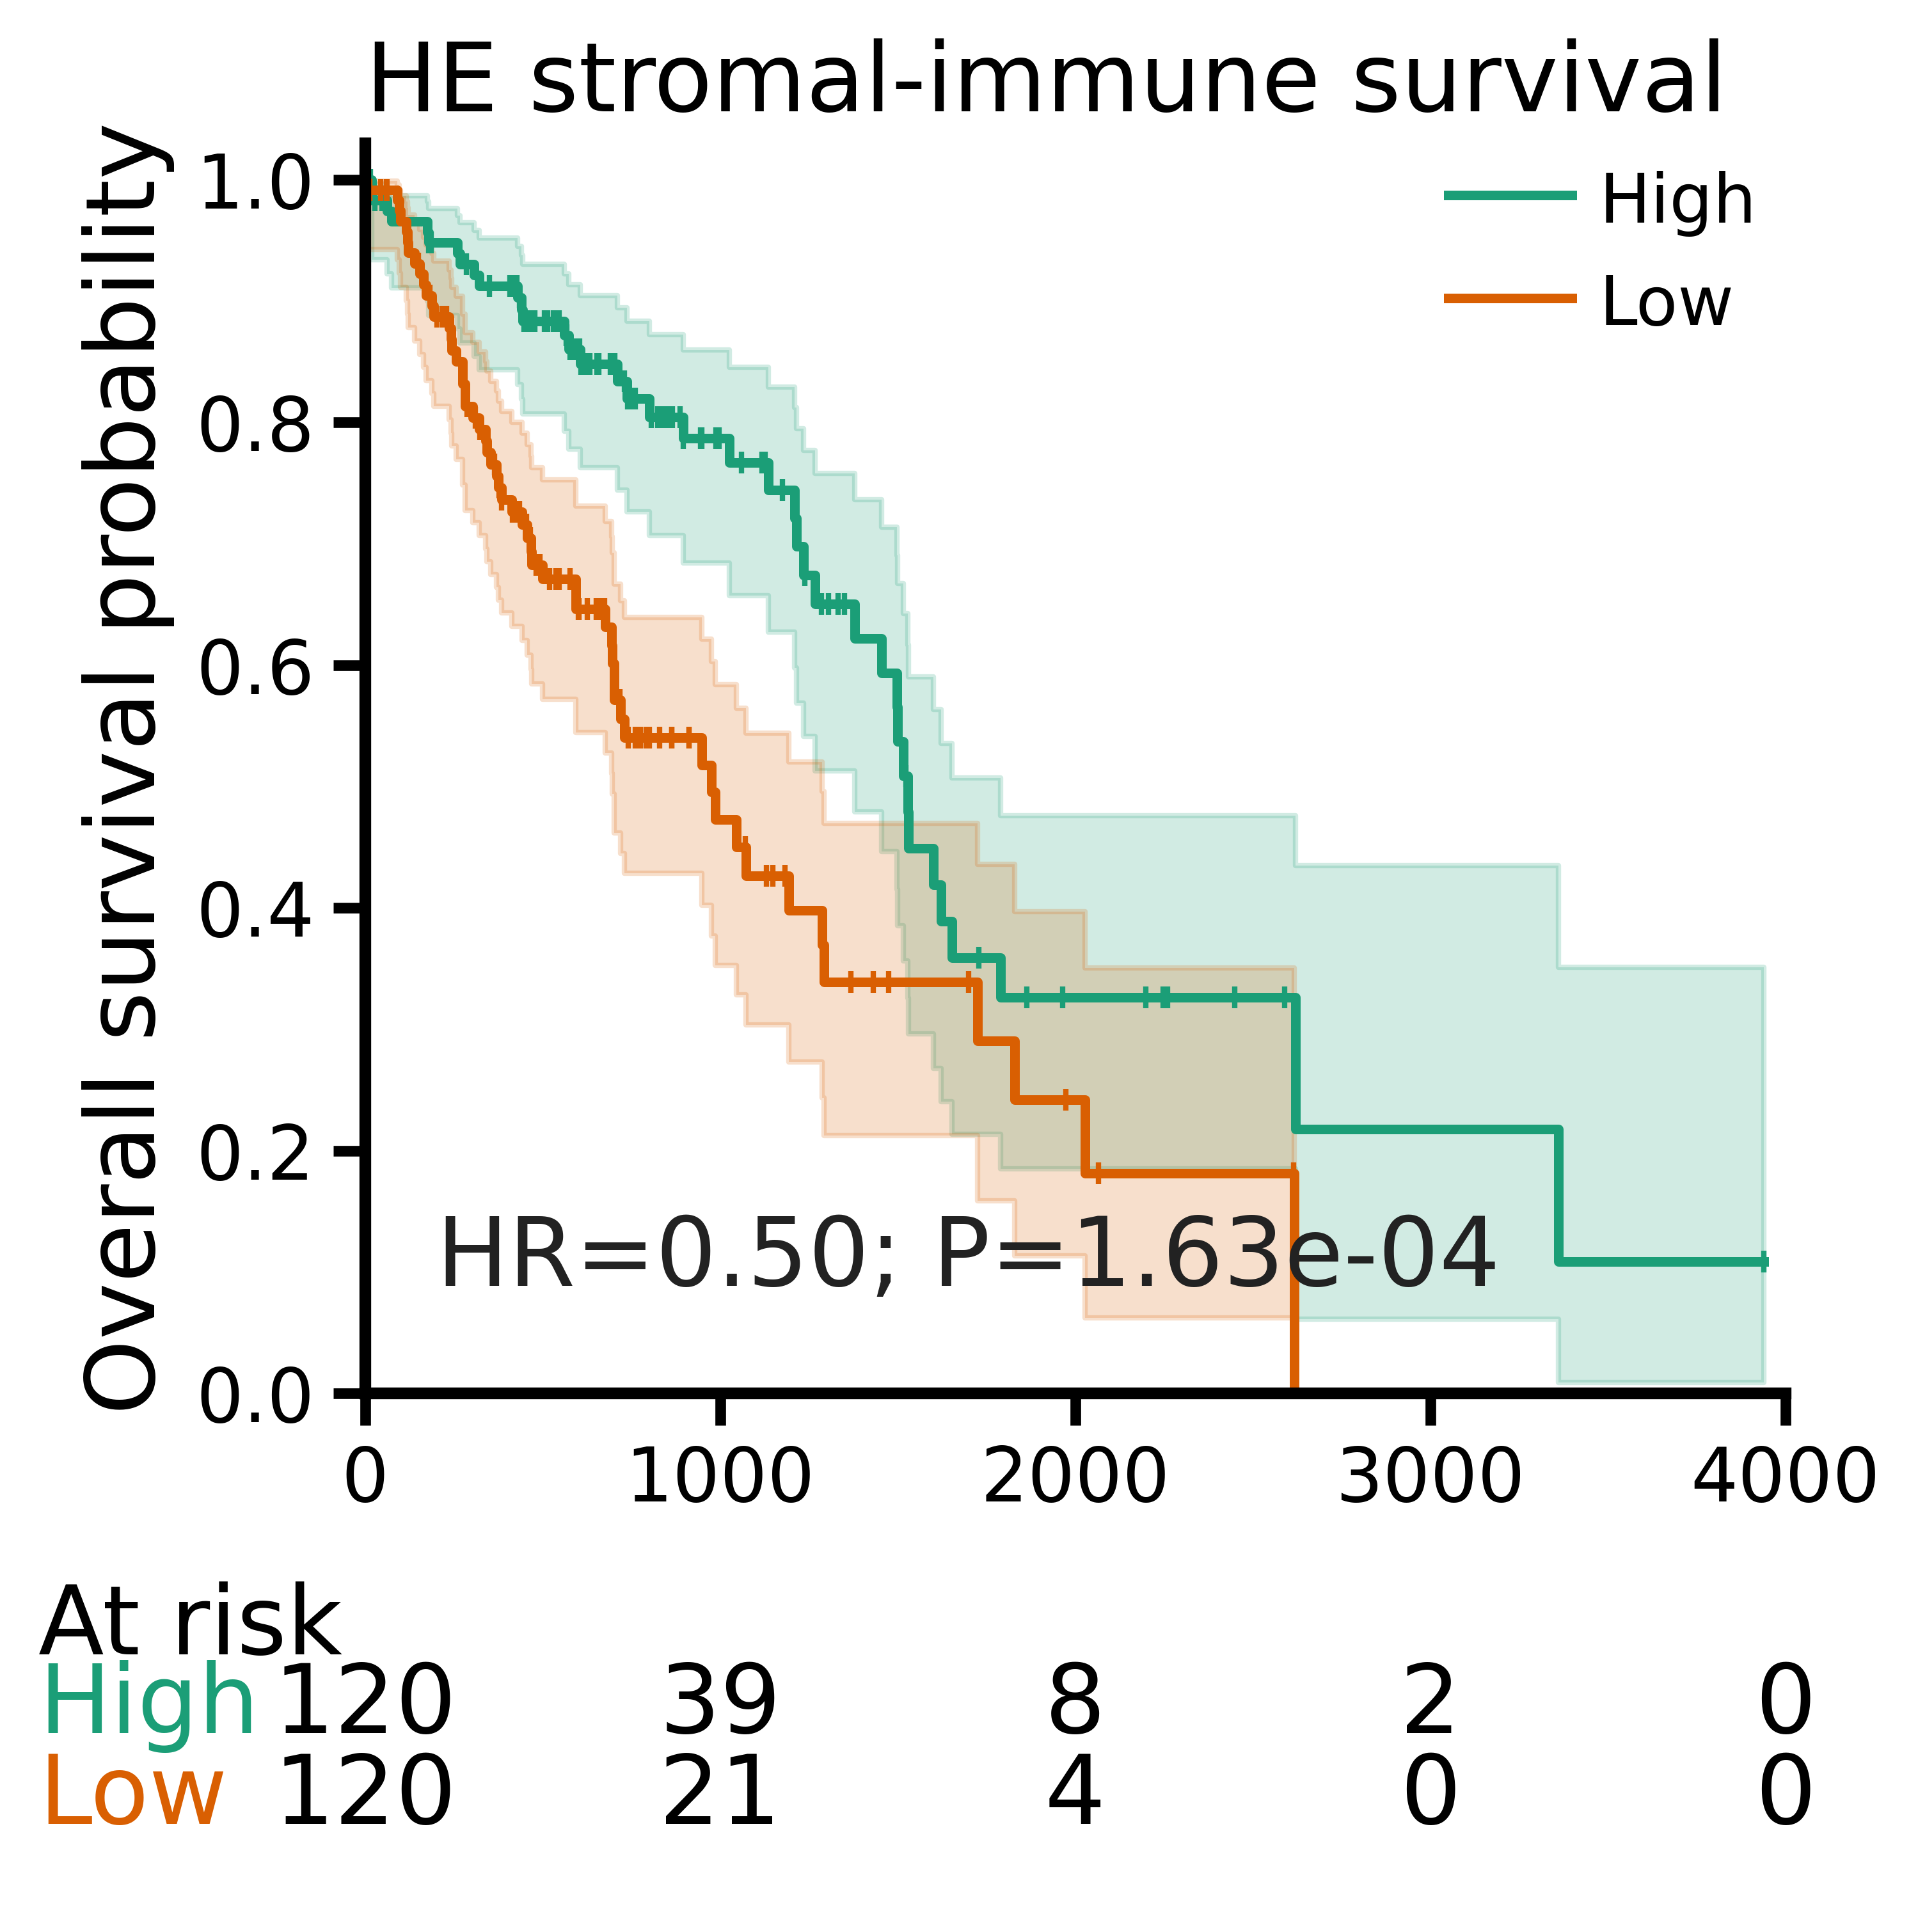

Saved: /data/hulei/OmicOS/OmicOS_7/outputs/figures/tcga_luad_survival/tcga_luad_all_available_he_stromal_immune_km_styled_omicos7.pdf
Saved: /data/hulei/OmicOS/OmicOS_7/outputs/figures/tcga_luad_survival/tcga_luad_all_available_he_stromal_immune_km_styled_omicos7.png
HR=0.5003, CI=(0.3387, 0.7391), Cox P=0.000504134, log-rank P=0.000163202


                    group    n  events
0  HE stromal-immune high  120      39
1   HE stromal-immune low  120      56

In [10]:

from pathlib import Path

import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from lifelines import CoxPHFitter, KaplanMeierFitter
from lifelines.statistics import logrank_test

ROOT = Path('/data/hulei/OmicOS/OmicOS_7')
DATASET = ROOT / 'outputs/tables/tcga_luad_all_available_he_stromal_immune_survival_dataset_omicos7.csv'
FIG_DIR = ROOT / 'outputs/figures/tcga_luad_survival'
FIG_DIR.mkdir(parents=True, exist_ok=True)

OUT_PNG = FIG_DIR / 'tcga_luad_all_available_he_stromal_immune_km_styled_omicos7.png'
OUT_PDF = FIG_DIR / 'tcga_luad_all_available_he_stromal_immune_km_styled_omicos7.pdf'

mpl.rcParams.update({
    'font.size': 18,
    'axes.titlesize': 18,
    'axes.labelsize': 18,
    'xtick.labelsize': 18,
    'ytick.labelsize': 18,
    'legend.fontsize': 18,
    'pdf.fonttype': 42,
    'ps.fonttype': 42,
    'axes.grid': False,
    'figure.dpi': 180,
    'savefig.dpi': 320,
})


ov.plot_set(font_path='Arial')
sc.settings.set_figure_params(dpi=300, vector_friendly=True)
plt.rcParams['pdf.fonttype'] = 42
plt.rcParams['ps.fonttype'] = 42

df = pd.read_csv(DATASET)
required = {'survival_days', 'event', 'he_stromal_immune_group'}
missing = sorted(required - set(df.columns))
if missing:
    raise ValueError(f'Missing required columns: {missing}')

df = df.replace([np.inf, -np.inf], np.nan).dropna(subset=['survival_days', 'event', 'he_stromal_immune_group']).copy()
df['survival_days'] = pd.to_numeric(df['survival_days'], errors='coerce')
df['event'] = pd.to_numeric(df['event'], errors='coerce')
df = df[(df['survival_days'] > 0) & df['event'].isin([0, 1])].copy()

high_label = 'HE stromal-immune high'
low_label = 'HE stromal-immune low'
plot_order = [high_label, low_label]
missing_groups = [g for g in plot_order if g not in set(df['he_stromal_immune_group'])]
if missing_groups:
    raise ValueError(f'Missing expected groups: {missing_groups}')

high = df[df['he_stromal_immune_group'] == high_label]
low = df[df['he_stromal_immune_group'] == low_label]
logrank = logrank_test(high['survival_days'], low['survival_days'], high['event'], low['event'])

cox_df = df[['survival_days', 'event', 'he_stromal_immune_group']].copy()
cox_df['he_stromal_immune_high'] = (cox_df['he_stromal_immune_group'] == high_label).astype(float)
cph = CoxPHFitter(penalizer=0.05)
cph.fit(cox_df[['survival_days', 'event', 'he_stromal_immune_high']], duration_col='survival_days', event_col='event')
cox_row = cph.summary.loc['he_stromal_immune_high']
hr = float(cox_row['exp(coef)'])
ci_low = float(cox_row['exp(coef) lower 95%'])
ci_high = float(cox_row['exp(coef) upper 95%'])
cox_p = float(cox_row['p'])

def format_pvalue(value):
    return f"{value:.2e}" if value < 0.001 else f"{value:.3f}"


def counts_at_risk(kmf, times):
    event_table = kmf.event_table.assign(at_risk_end=lambda x: x['at_risk'] - x['removed'])
    counts = []
    for time in times:
        rows = event_table.loc[event_table.index <= time]
        if rows.empty:
            counts.append(int(event_table['at_risk'].iloc[0]))
        elif time == 0:
            counts.append(int(rows['at_risk'].iloc[-1]))
        else:
            counts.append(int(rows['at_risk_end'].iloc[-1]))
    return counts


fig = plt.figure(figsize=(5.0, 6.0), constrained_layout=False)
gs = fig.add_gridspec(nrows=2, ncols=1, height_ratios=[4.6, 1.0], hspace=0.30)
ax = fig.add_subplot(gs[0])
ax_risk = fig.add_subplot(gs[1], sharex=ax)
colors = {
    high_label: '#1B9E77',
    low_label: '#D95F02',
}
display_labels = {
    high_label: 'High',
    low_label: 'Low',
}
fitters = {}
for label in plot_order:
    group = df[df['he_stromal_immune_group'] == label]
    display_label = display_labels[label]
    kmf = KaplanMeierFitter(label=display_label)
    kmf.fit(group['survival_days'], event_observed=group['event'])
    kmf.plot_survival_function(
        ax=ax,
        ci_show=True,
        ci_alpha=0.20,
        color=colors[label],
        linewidth=1.8,
        show_censors=True,
        censor_styles={'ms': 4.0, 'marker': '|'},
    )
    fitters[label] = kmf

ax.grid(False)
ax.set_axisbelow(False)
ax.set_title('HE stromal-immune survival', loc='left',fontsize=18)
ax.set_xlabel('Days', labelpad=8,fontsize=18)
ax.set_ylabel('Overall survival probability',fontsize=18)
ax.set_ylim(0, 1.03)
max_time = int(np.ceil(df['survival_days'].max() / 1000.0) * 1000)
time_ticks = np.arange(0, max_time + 1, 1000)
ax.set_xlim(0, max_time)
ax.set_xticks(time_ticks)

for side in ['top', 'right']:
    ax.spines[side].set_visible(False)
for side in ['left', 'bottom']:
    ax.spines[side].set_linewidth(2.2)
    ax.spines[side].set_color('black')
ax.tick_params(axis='both', which='both', width=2.0, length=6, color='black', labelcolor='black')
ax.tick_params(axis='x', which='both', labelbottom=True, bottom=True)

legend = ax.legend(frameon=False, loc='upper right', bbox_to_anchor=(0.98, 0.98), handlelength=1.8, borderaxespad=0.0)

p_text = format_pvalue(logrank.p_value)
cox_p_text = format_pvalue(cox_p)
annotation = f"HR={hr:.2f}; P={p_text}"
ax.text(
    0.05,
    0.07,
    annotation,
    transform=ax.transAxes,
    ha='left',
    va='bottom',
    fontsize=18,
    color='#222222',
)

ax_risk.grid(False)
ax_risk.set_ylim(-0.4, 2.0)
ax_risk.set_yticks([])
ax_risk.set_xticks(time_ticks)
ax_risk.tick_params(axis='x', which='both', bottom=False, labelbottom=False, width=0, length=0,labelsize=18)
ax_risk.tick_params(axis='y', which='both', left=False, labelleft=False, width=0, length=0,labelsize=18)
for side in ['top', 'right', 'left', 'bottom']:
    ax_risk.spines[side].set_visible(False)

risk_rows = [(high_label, 1.25), (low_label, 0.45)]
ax_risk.text(-0.23, 1.95, 'At risk', transform=ax_risk.get_yaxis_transform(), ha='left', va='center', fontsize=18, clip_on=False)
for label, y in risk_rows:
    counts = counts_at_risk(fitters[label], time_ticks)
    ax_risk.text(-0.23, y, display_labels[label], transform=ax_risk.get_yaxis_transform(), ha='left', va='center', fontsize=18, color=colors[label], clip_on=False)
    for x, count in zip(time_ticks, counts):
        ax_risk.text(x, y, str(count), ha='center', va='center',  fontsize=18, color='black')

fig.subplots_adjust(left=0.23, right=0.97, top=0.90, bottom=0.14)
fig.savefig(OUT_PDF)
fig.savefig(OUT_PNG)
plt.show()

summary = pd.DataFrame([
    {
        'group': label,
        'n': int((df['he_stromal_immune_group'] == label).sum()),
        'events': int(df.loc[df['he_stromal_immune_group'] == label, 'event'].sum()),
    }
    for label in plot_order
])
print(f'Saved: {OUT_PDF}')
print(f'Saved: {OUT_PNG}')
print(f'HR={hr:.4f}, CI=({ci_low:.4f}, {ci_high:.4f}), Cox P={cox_p:.6g}, log-rank P={logrank.p_value:.6g}')
display(summary)


In [6]:
help(ax_risk.tick_params)

Help on method tick_params in module matplotlib.axes._base:

tick_params(axis='both', **kwargs) method of matplotlib.axes._axes.Axes instance
    Change the appearance of ticks, tick labels, and gridlines.
    
    Tick properties that are not explicitly set using the keyword
    arguments remain unchanged unless *reset* is True. For the current
    style settings, see `.Axis.get_tick_params`.
    
    Parameters
    ----------
    axis : {'x', 'y', 'both'}, default: 'both'
        The axis to which the parameters are applied.
    which : {'major', 'minor', 'both'}, default: 'major'
        The group of ticks to which the parameters are applied.
    reset : bool, default: False
        Whether to reset the ticks to defaults before updating them.
    
    Other Parameters
    ----------------
    direction : {'in', 'out', 'inout'}
        Puts ticks inside the Axes, outside the Axes, or both.
    length : float
        Tick length in points.
    width : float
        Tick width in point